# Multivariate Statistics with Korean Weather Station Data
### Chapter 9. Cluster Analysis · Chapter 10. Multidimensional Scaling · Chapter 11. Discriminant Analysis

**Learning objectives**
1. Explore weather-station data and understand distance and standardization.
2. Group similar stations using K-means and hierarchical clustering.
3. Compare cluster means, distributions, seasonal and diurnal patterns, and geographic locations.
4. Compare clusters based only on averages with clusters that also include temporal features.
5. Explain how multidimensional scaling (MDS) and discriminant analysis (LDA) differ from clustering.

**Textbook:** Ken Butler, *Using Statistical Methods in R: A How-to Guide* (2014), Chapters 9–11.

This is a statistical exercise based on Korean weather-station observations. The purpose is **not** to establish the causes of regional differences or define official climate zones.

## Getting started: Colab and GitHub

The notebooks and `Weather_Statistics_Data.zip` can be uploaded **as separate files at the root of the same GitHub repository**. The first code cell clones the repository in Colab (when necessary) and unpacks the data automatically.

```text
weather-statistics/
├── Weather_Statistics_Ch09-11_EN.ipynb
├── Weather_Statistics_Ch09-11_KO.ipynb
└── Weather_Statistics_Data.zip
```

**Before sharing:** Replace `GITHUB_REPO_URL` in the first code cell of both notebooks with the actual repository URL. The link must point to a repository that students can access. In Colab, open a notebook from GitHub, then select **Runtime → Run all**. The notebook does not require manual CSV uploads.

For local use, place the notebook next to the data ZIP. The first cell also unpacks it locally. The original hourly observations are **not** loaded during the seminar; compact station-level summaries are used instead.

In [1]:
# Replace with the actual repository URL BEFORE sharing the notebook.
# Example: https://github.com/example-lab/weather-statistics.git
GITHUB_REPO_URL = "https://github.com/YOUR_ACCOUNT/YOUR_REPOSITORY.git"

# In Colab, automatically clone the GitHub repository and unzip the data.
# Locally, place the data ZIP in the same directory as the notebook.
from pathlib import Path
import os, sys, subprocess, zipfile

DATA_ZIP_NAME = "Weather_Statistics_Data.zip"
IS_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))

if not Path("data/station_features.csv").exists():
    if not Path(DATA_ZIP_NAME).exists() and IS_COLAB:
        if "YOUR_ACCOUNT" in GITHUB_REPO_URL or "YOUR_REPOSITORY" in GITHUB_REPO_URL:
            raise ValueError("Before distribution, replace GITHUB_REPO_URL with your actual GitHub repository URL.")
        repo_name = GITHUB_REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
        target = Path("/content") / repo_name
        if not target.exists():
            subprocess.run(["git", "clone", "--depth", "1", GITHUB_REPO_URL, str(target)], check=True)
        os.chdir(target)
    if not Path("data/station_features.csv").exists():
        if not Path(DATA_ZIP_NAME).exists():
            raise FileNotFoundError(f"Place {DATA_ZIP_NAME} in this folder or in the GitHub repository.")
        with zipfile.ZipFile(DATA_ZIP_NAME) as archive:
            archive.extractall(".")

assert Path("data/station_features.csv").exists(), "The data setup was not successful."
print("Data ready:", Path.cwd().resolve())


Data ready: /mnt/data/Weather_Statistics_Final_GitHub/_execute_tmp


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import pdist, squareform
from sklearn.manifold import MDS
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import confusion_matrix, accuracy_score

plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
DATA = Path('data')
assert (DATA / 'station_features.csv').exists(), 'The data/ folder must be in the working directory.'
SEED = 42

### Choose the number of clusters

Change the single **`K`** value below to use the same number of clusters in Models A and B (K-means, hierarchical clustering, and maps). The default is **K = 4**. After changing it, select **Run all**. There is no universally correct K; also consider cluster size and interpretation.

In [3]:
K = 4  # Examples: 2, 3, 4, 5, 6, 7, 8
assert isinstance(K, int) and 2 <= K <= 8, 'K must be an integer between 2 and 8.'
print(f'Current number of clusters: K = {K}')

Current number of clusters: K = 4


---
# 0. Understanding and Exploring the Data

**Dataset:** Hourly weather observations from South Korea, 2021–2024. We use **370 weather stations** with at least 80% annual data coverage for all four variables (temperature, relative humidity, wind speed, and hourly precipitation). Station-coordinate stability was also considered during selection.

| Variable | Meaning | Unit |
|---|---|---|
| Temperature (TA) | Air temperature | °C |
| Relative humidity (HM) | Relative humidity of the air | % |
| Wind speed (WS) | Wind speed | m/s |
| Hourly precipitation (RN) | Precipitation accumulated in an hourly interval | mm/h (hourly reporting basis) |

**Unit of analysis:** The source is `station × hour`, but **each row** in clustering represents **one weather station**. Hourly measurements are summarized into long-term means and temporal characteristics.

In [4]:
site = pd.read_csv(DATA / 'station_features.csv').sort_values('station_id').reset_index(drop=True)
monthly = pd.read_csv(DATA / 'monthly_profiles.csv')
hourly = pd.read_csv(DATA / 'hourly_profiles.csv')
season = pd.read_csv(DATA / 'season_profiles.csv')
qa = pd.read_csv(DATA / 'source_qa.csv')
MEAN = ['ta_mean', 'hm_mean', 'ws_mean', 'rn_hr1_mean']
NAMES = {'ta_mean':'Temperature (°C)', 'hm_mean':'Relative humidity (%)',
         'ws_mean':'Wind speed (m/s)', 'rn_hr1_mean':'Mean hourly precipitation (mm/h)'}
VARS = ['ta', 'hm', 'ws', 'rn_hr1']
VAR_NM = {'ta':'Temperature (°C)', 'hm':'Relative humidity (%)',
          'ws':'Wind speed (m/s)', 'rn_hr1':'Hourly precipitation (mm/h)'}
print(f'Stations: {len(site)}, clustering matrix: stations × {len(MEAN)} features')
display(site[['station_id','latitude','longitude'] + MEAN].head().rename(columns=NAMES))

Stations: 370, clustering matrix: stations × 4 features


,station_id,latitude,longitude,Temperature (°C),Relative humidity (%),Wind speed (m/s),Mean hourly precipitation (mm/h)
0,12,36.5333,126.3167,13.52041,73.39329,2.774807,0.131874
1,96,37.2395,131.8698,14.83468,74.30939,4.052108,0.081869
2,116,37.4453,126.9640,10.39278,70.46011,2.697599,0.189782
3,160,35.1188,129.0000,12.38998,69.53195,4.966446,0.166536
4,175,34.4721,126.3238,12.73144,83.88996,4.340485,0.180807


## 0.1 Descriptive statistics and data coverage

The mean describes central tendency; the standard deviation describes between-station variation. Minimum and maximum values can reveal unusually high or low station values. **The table below describes the distribution of long-term station means, not the hourly observations themselves.**

In [5]:
display(site[MEAN].rename(columns=NAMES).describe().loc[['mean','std','min','25%','50%','75%','max']].round(2))
display(qa[['year','variable','valid_share']].pivot(index='year',columns='variable',values='valid_share').round(3))

,Temperature (°C),Relative humidity (%),Wind speed (m/s),Mean hourly precipitation (mm/h)
mean,13.20,72.76,2.06,0.17
std,1.91,4.65,1.03,0.07
min,6.09,58.23,0.67,0.06
25%,12.11,70.05,1.38,0.14
50%,13.45,73.22,1.74,0.16
75%,14.42,75.76,2.48,0.17
max,17.89,84.86,6.96,0.76


variable,hm,rn_hr1,ta,ws
year,,,,
2021,0.866,0.973,0.984,0.982
2022,0.947,0.985,0.992,0.990
2023,0.987,0.987,0.995,0.994
2024,0.984,0.977,0.991,0.988


## 0.2 Distributions of the variables

Histograms show how the station-level mean weather conditions vary across stations. Extreme values may influence clustering.

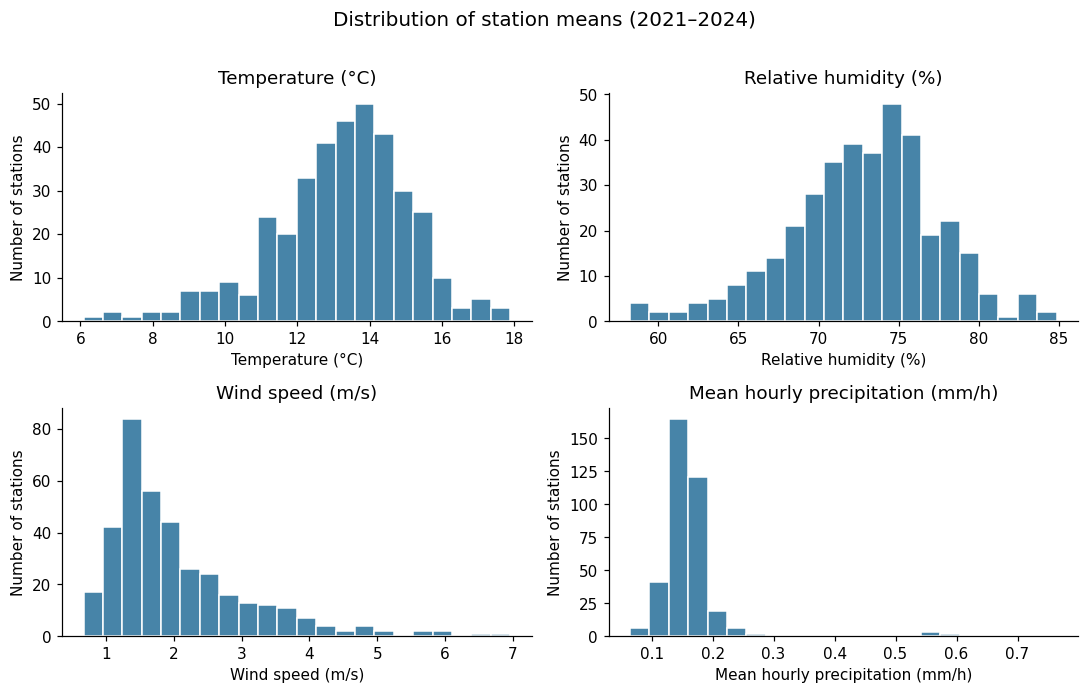

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for ax, col in zip(axes.flat, MEAN):
    ax.hist(site[col], bins=22, color='#4784a8', edgecolor='white')
    ax.set(title=NAMES[col], xlabel=NAMES[col], ylabel='Number of stations')
plt.suptitle('Distribution of station means (2021–2024)', y=1.01, fontsize=13)
plt.tight_layout(); plt.show()

## 0.3 Relationships between variables: scatter plots and correlations

Each point in the scatter plots represents **one weather station**. Pearson's correlation coefficient summarizes linear association between variables. Correlation does not imply causation.

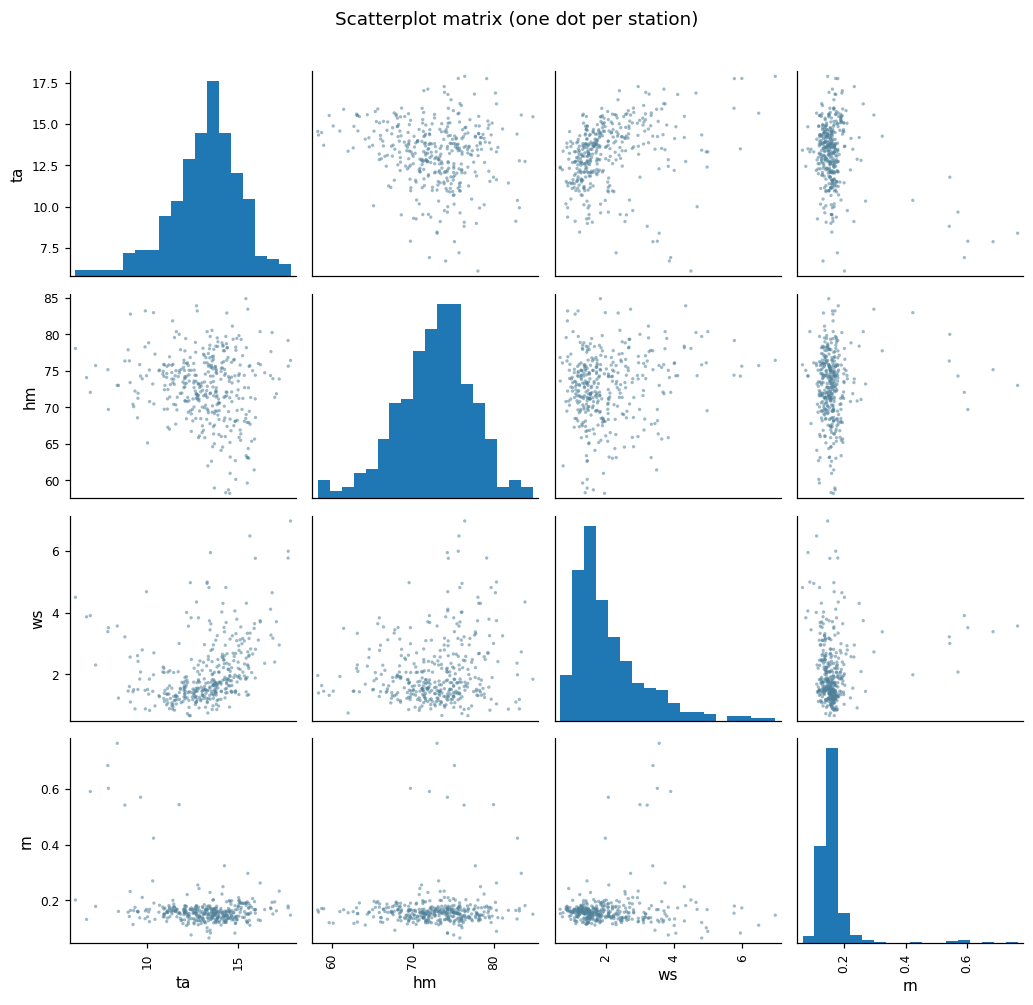

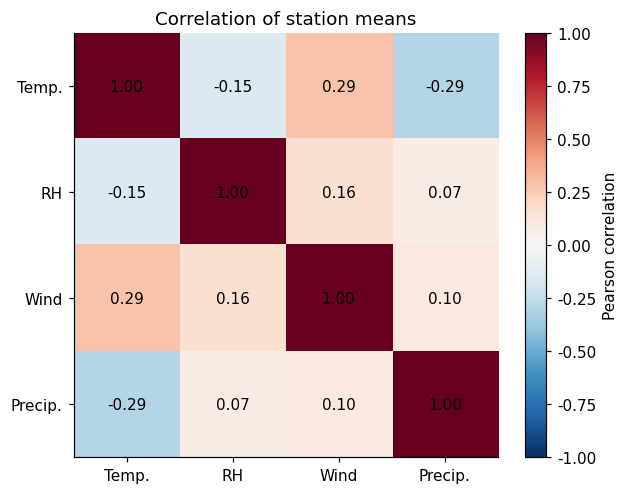

In [7]:
axes = pd.plotting.scatter_matrix(site[MEAN].rename(columns={x:x.split('_')[0] for x in MEAN}),
                                  figsize=(9.5,9), diagonal='hist', alpha=.55,
                                  color='#4f8099', s=19, hist_kwds={'bins':18})
plt.suptitle('Scatterplot matrix (one dot per station)', y=1.01)
plt.tight_layout(); plt.show()

corr=site[MEAN].corr()
fig,ax=plt.subplots(figsize=(5.9,4.6))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(4),['Temp.','RH','Wind','Precip.']); ax.set_yticks(range(4),['Temp.','RH','Wind','Precip.'])
for i in range(4):
    for j in range(4):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
plt.colorbar(im,ax=ax,label='Pearson correlation'); ax.set_title('Correlation of station means')
plt.tight_layout();plt.show()

## 0.4 Spatial distribution of the stations

Plot station longitude and latitude over a coastline map. Notice where stations are concentrated or sparse before interpreting cluster maps. The simplified coastline is provided for instructional mapping; it does not describe administrative boundaries or the representativeness of the monitoring network.

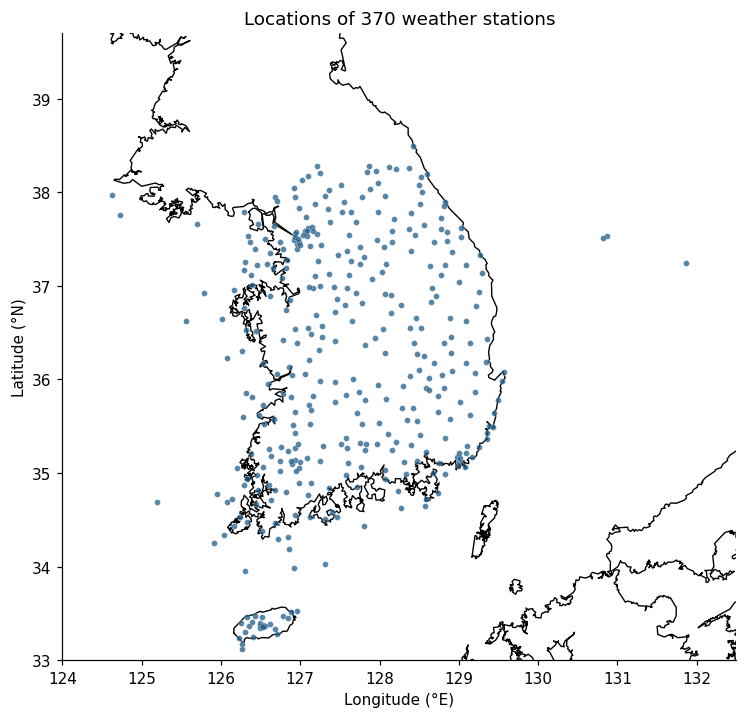

In [8]:
coast = json.loads((DATA / 'korea_coastline.json').read_text(encoding='utf-8'))['segments']
def draw_coast(ax):
    ax.set_facecolor('white')
    for seg in coast:
        xy=np.array(seg)
        ax.plot(xy[:,0],xy[:,1],color='black',lw=0.9,zorder=1)
    ax.set_xlim(124,132.5); ax.set_ylim(33,39.7)
    ax.set_aspect(1.18)
    ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)')
    ax.grid(False)

fig,ax=plt.subplots(figsize=(7,6.6))
draw_coast(ax)
ax.scatter(site.longitude,site.latitude,s=15,c='#215e88',alpha=.75,edgecolors='white',linewidths=.2,zorder=2)
ax.set_title(f'Locations of {len(site)} weather stations')
plt.tight_layout();plt.show()

---
# Chapter 9. Cluster Analysis

## 9.1 What is clustering?

Clustering is a method for **grouping observations that are similar to one another**. Because there are no pre-assigned correct group labels, it is a form of **unsupervised learning**.

Each station is treated as one observation. In Model A, we ask whether stations have similar **long-term mean weather conditions**.

| Method | Main idea | Main output |
|---|---|---|
| K-means | Assign observations to nearby centroids | K groups and their centers |
| Hierarchical clustering | Successively merge nearby observations or groups | A dendrogram and groups |

The two methods can produce different group assignments even on the same dataset.

## 9.1 Distance and standardization

Similarity between two stations can be quantified by **distance**. For two points \(x_1,y_1\) and \(x_2,y_2\), Euclidean distance is

\[
d=\sqrt{(x_1-x_2)^2+(y_1-y_2)^2}
\]

Temperature (°C), humidity (%), wind speed (m/s), and precipitation (mm/h) have different units and numerical ranges. Without a scale adjustment, one variable may dominate the distance calculation. We therefore use **Z-score standardization**:

\[
z=\frac{x-\bar{x}}{s}
\]

A standardized value describes a station's position relative to other stations, rather than its weather value in physical units.

In [9]:
X_A = StandardScaler().fit_transform(site[MEAN])
example=site[['station_id','ta_mean']].head(4).copy()
example['Temperature Z-score']=X_A[:4,0]
display(example.rename(columns={'station_id':'Station','ta_mean':'Mean temperature (°C)'}).round(2))
print('Number of standardized features:', X_A.shape[1])

,Station,Mean temperature (°C),Temperature Z-score
0,12,13.52,0.17
1,96,14.83,0.86
2,116,10.39,-1.47
3,160,12.39,-0.42


Number of standardized features: 4


## 9.3 Elbow method: How many clusters should we use?

K-means requires a specified number of clusters, **K**. The **within-cluster sum of squares (WCSS or WSS)** is the sum of squared distances between stations and their assigned cluster centers. WCSS generally decreases as K increases. The Elbow method looks for a point where the decrease becomes noticeably smaller.

**Caution:** A clear elbow may not exist. If it does not, choose K with the learning or interpretation goal in mind. The default for this exercise is **K = 4**.

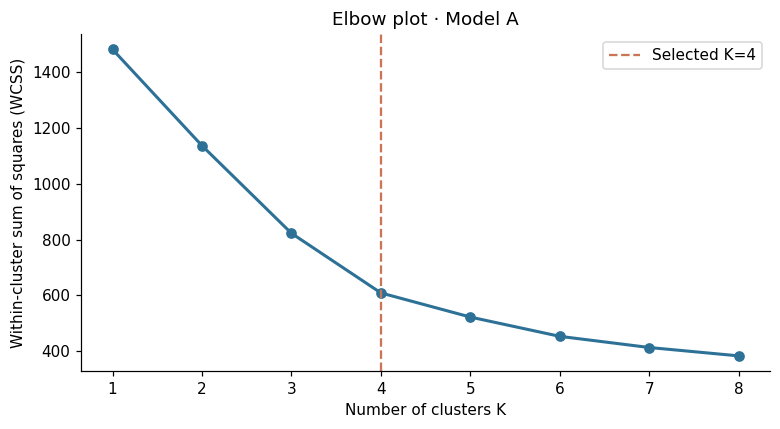

In [10]:
k_values=range(1,9)
wcss=[KMeans(n_clusters=k,random_state=SEED,n_init=20).fit(X_A).inertia_ for k in k_values]
fig,ax=plt.subplots(figsize=(7.2,4))
ax.plot(list(k_values),wcss,'o-',color='#2d7197',lw=2)
ax.axvline(K,color='#ca7656',ls='--',label=f'Selected K={K}')
ax.set(xlabel='Number of clusters K',ylabel='Within-cluster sum of squares (WCSS)',title='Elbow plot · Model A')
ax.set_xticks(list(k_values));ax.legend()
plt.tight_layout();plt.show()

## 9.3 K-means clustering — Model A

K-means repeats these steps:

1. Initialize K cluster centers.
2. Assign each station to its nearest center.
3. Recalculate each center as the mean of its assigned stations.
4. Repeat until assignments stabilize.

**Model A inputs:** Mean temperature, relative humidity, wind speed, and hourly precipitation (**4 variables**). Cluster labels C1, C2, and so on are **arbitrary identifiers, not ranks**.

In [11]:
km_a=KMeans(n_clusters=K,random_state=SEED,n_init=30)
site['cluster_A']=km_a.fit_predict(X_A)+1
print(f'Model A · K-means · K={K}')
display(site.cluster_A.value_counts().sort_index().rename_axis('Cluster').to_frame('Number of stations'))

Model A · K-means · K=4


,Number of stations
Cluster,
1,77
2,8
3,187
4,98


## 9.2 Hierarchical clustering

Agglomerative hierarchical clustering begins with one group per station and merges the most similar groups step by step. A **dendrogram** displays the sequence of merges.

The group-to-group linkage can be defined by **Single linkage (closest pair)**, **Complete linkage (farthest pair)**, or **Ward's method (increase in within-cluster variation when merging)**. We use **Ward's method**, which is also introduced in the textbook. The key idea is that different merging rules can produce different trees.

**Reading the dendrogram:** Every leaf on the x-axis is a station; only some station codes are printed to avoid overlap. The red dashed line is the cut that produces the chosen `K` clusters. Stations joined below the cut belong to the same hierarchical group.

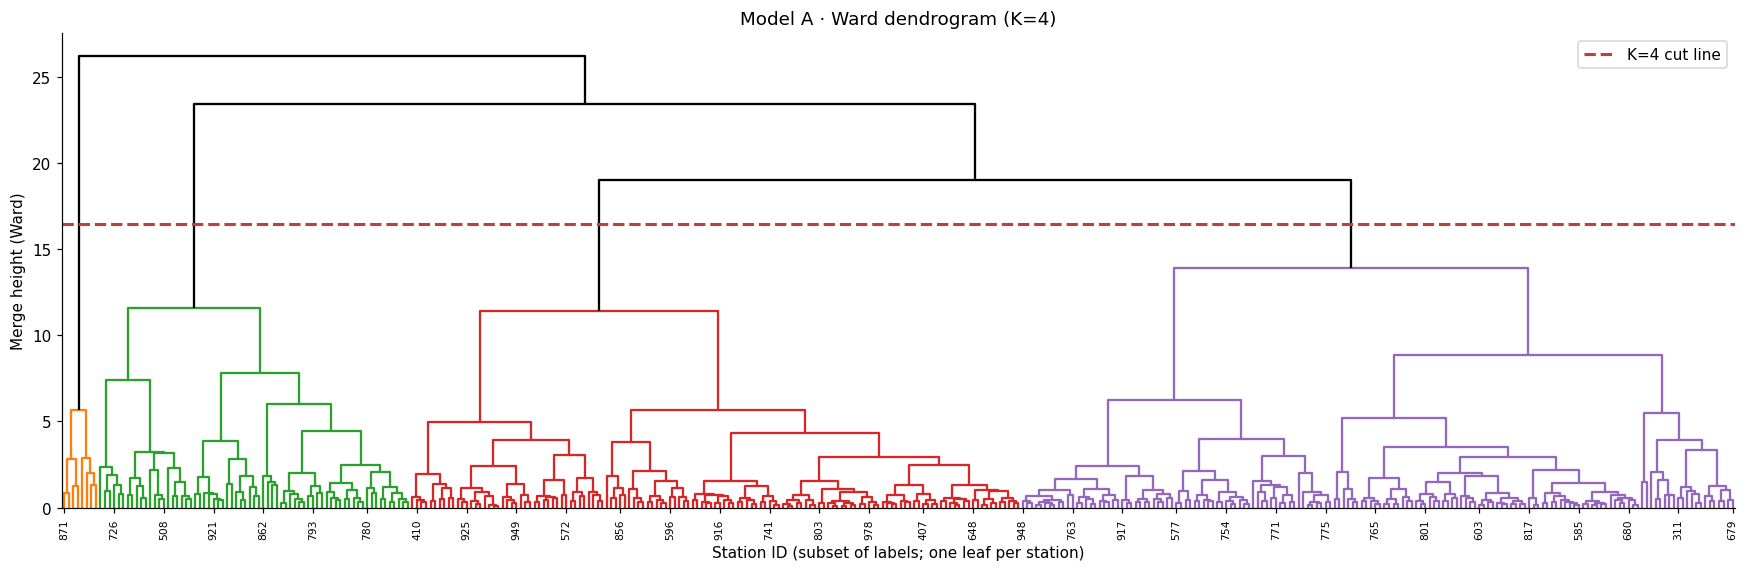

,Number of stations
Cluster,
1,8
2,69
3,135
4,158


In [12]:
def station_dendrogram(Z, station_codes, n_clusters, title):
    """Plot all stations but print only some station IDs on the x-axis."""
    # Cut midway between the final merge for K groups and the next merge
    cut_height = (Z[-n_clusters, 2] + Z[-(n_clusters-1), 2]) / 2
    fig, ax = plt.subplots(figsize=(16, 5.3), facecolor='white')
    tree = dendrogram(Z, ax=ax, no_labels=True, color_threshold=cut_height,
                      above_threshold_color='black')
    ax.axhline(cut_height, color='#c13e3e', linewidth=2, linestyle='--',
               label=f'K={n_clusters} cut line')
    # Print only selected station IDs to avoid overlapping tick labels
    leaves = np.asarray(tree['leaves'])
    step_positions = np.unique(np.linspace(0, len(leaves)-1, min(34,len(leaves)), dtype=int))
    ax.set_xticks(5 + 10*step_positions)
    ax.set_xticklabels([str(station_codes.iloc[leaves[pos]]) for pos in step_positions],
                       rotation=90, fontsize=7)
    ax.set(xlabel='Station ID (subset of labels; one leaf per station)',
           ylabel='Merge height (Ward)', title=title)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()
    return cut_height

link_A = linkage(X_A, method='ward')
site['hier_A'] = fcluster(link_A, t=K, criterion='maxclust')
cut_A = station_dendrogram(link_A, site['station_id'], K,
                           f'Model A · Ward dendrogram (K={K})')
display(site.hier_A.value_counts().sort_index().rename_axis('Cluster').to_frame('Number of stations'))

## Model A cluster profiles ① — Spatial distribution

Plot the stations in each cluster on a simplified coastline map of Korea. This helps identify whether clusters are geographically concentrated. However, **geographic proximity alone cannot establish the cause of the weather differences**.

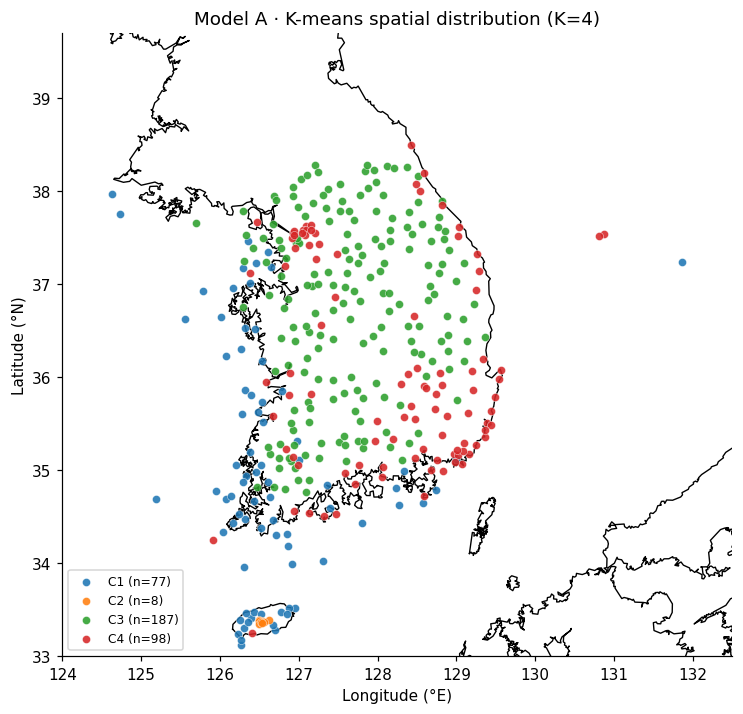

In [13]:
colors = plt.get_cmap('tab10').colors
def cluster_map(ax,labels,title):
    draw_coast(ax)
    for cl in range(1,K+1):
        subset=site.loc[np.asarray(labels)==cl]
        ax.scatter(subset.longitude,subset.latitude,s=28,
                   color=colors[(cl-1)%10],edgecolor='white',lw=.3,
                   alpha=.88,label=f'C{cl} (n={len(subset)})',zorder=2)
    ax.set_title(title)
    ax.legend(loc='lower left',fontsize=8,frameon=True)

fig,ax=plt.subplots(figsize=(7.2,6.6))
cluster_map(ax,site.cluster_A,f'Model A · K-means spatial distribution (K={K})')
plt.tight_layout();plt.show()

## Model A cluster profiles ② — Mean weather conditions

Compare the **mean values in their original units** to see how groups differ. Because these same means were used to define Model A, the differences are **descriptive explanations of the clusters**, not independent confirmation of their validity.

,Number of stations,Temperature (°C),Relative humidity (%),Wind speed (m/s),Mean hourly precipitation (mm/h)
cluster_A,,,,,
1,77,14.73,76.58,3.39,0.15
2,8,8.96,75.43,3.08,0.59
3,187,12.14,73.96,1.51,0.16
4,98,14.36,67.24,1.99,0.16


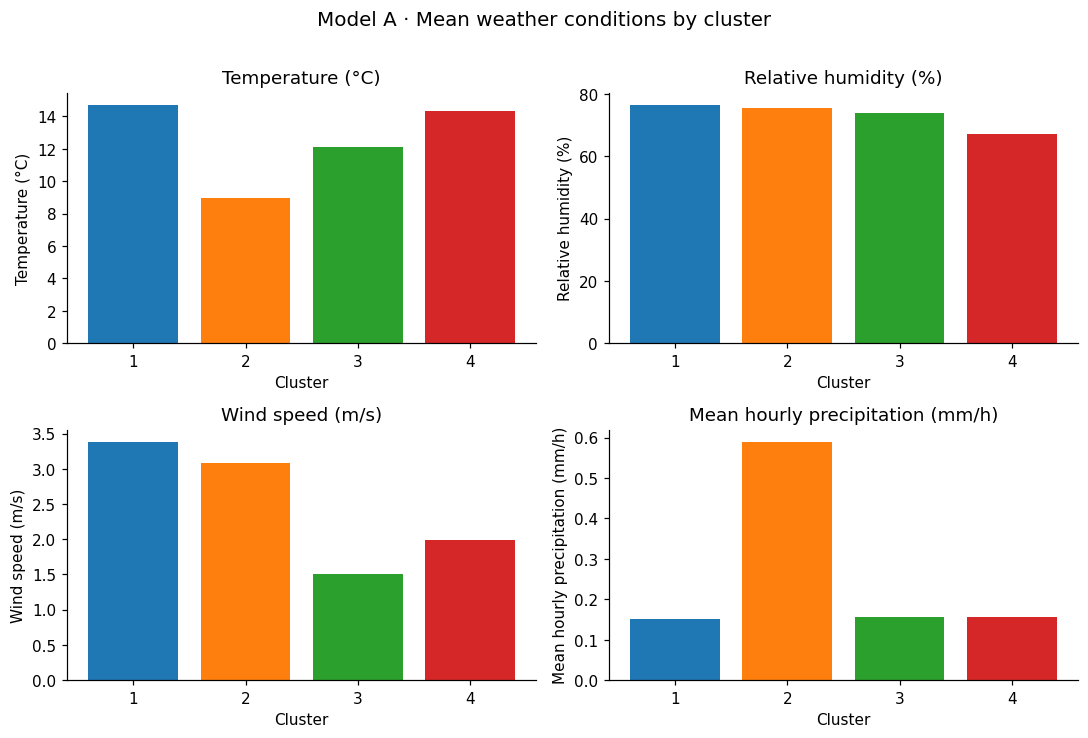

In [14]:
means_a=site.groupby('cluster_A')[MEAN].mean().rename(columns=NAMES)
counts_a=site.cluster_A.value_counts().sort_index()
means_a.insert(0,'Number of stations',counts_a)
display(means_a.round(2))
fig,axes=plt.subplots(2,2,figsize=(10,6.6))
colors=plt.get_cmap('tab10').colors
for ax,col in zip(axes.flat,MEAN):
    vals=site.groupby('cluster_A')[col].mean()
    ax.bar(vals.index.astype(str),vals.values,color=[colors[int(i-1)%10] for i in vals.index])
    ax.set(title=NAMES[col],xlabel='Cluster',ylabel=NAMES[col])
plt.suptitle('Model A · Mean weather conditions by cluster',y=1.01,fontsize=13)
plt.tight_layout();plt.show()

## Model A cluster profiles ③ — Distributions across stations

Groups can differ in their spread even if their means are similar. In the **boxplots**, the center line is the median, the box spans the middle 50%, and separately plotted points are potential outliers under the boxplot rule.

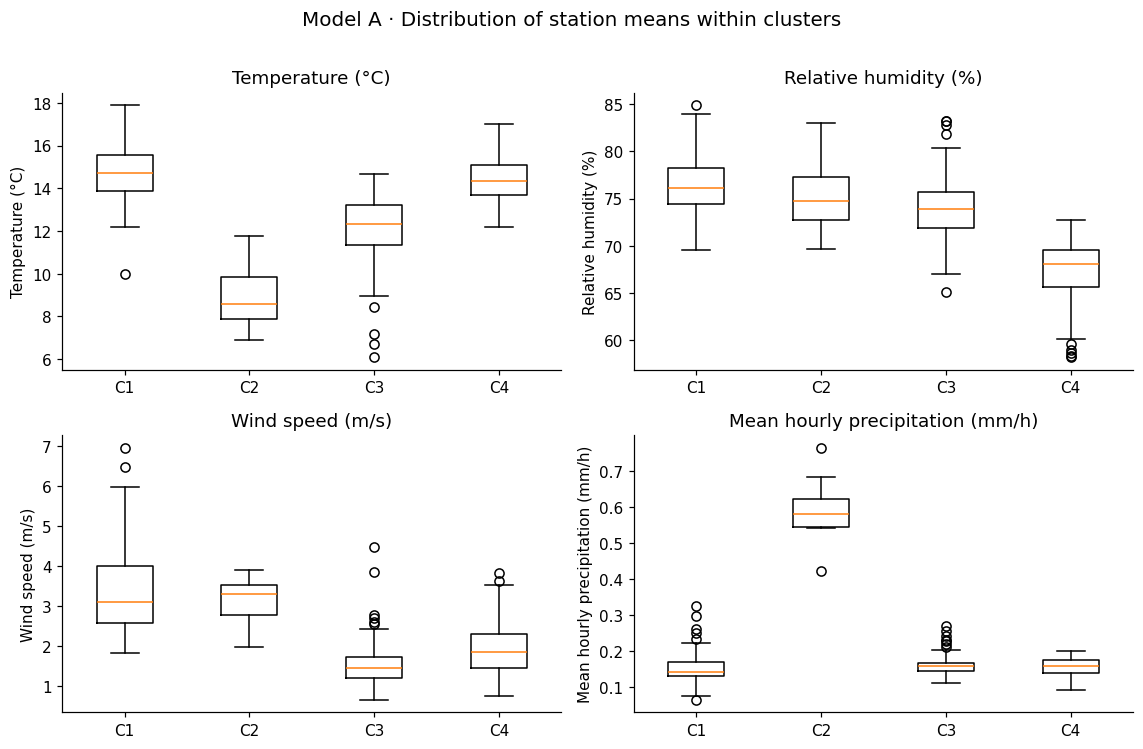

In [15]:
fig,axes=plt.subplots(2,2,figsize=(10.5,6.7))
for ax,col in zip(axes.flat,MEAN):
    groups=[site.loc[site.cluster_A==i,col].to_numpy() for i in range(1,K+1)]
    ax.boxplot(groups,tick_labels=[f'C{i}' for i in range(1,K+1)],showfliers=True)
    ax.set(title=NAMES[col],ylabel=NAMES[col])
plt.suptitle('Model A · Distribution of station means within clusters',y=1.01,fontsize=13)
plt.tight_layout();plt.show()

## Model A cluster profiles ④ — Monthly (seasonal) patterns

To obtain each cluster's monthly profile, average the monthly station values within that cluster for months 1–12. Model A does **not** use monthly variation as a clustering input, so these plots can reveal temporal features of clusters defined using only overall means.

*These are average monthly cycles pooled across 2021–2024, not trends or year-by-year changes.*

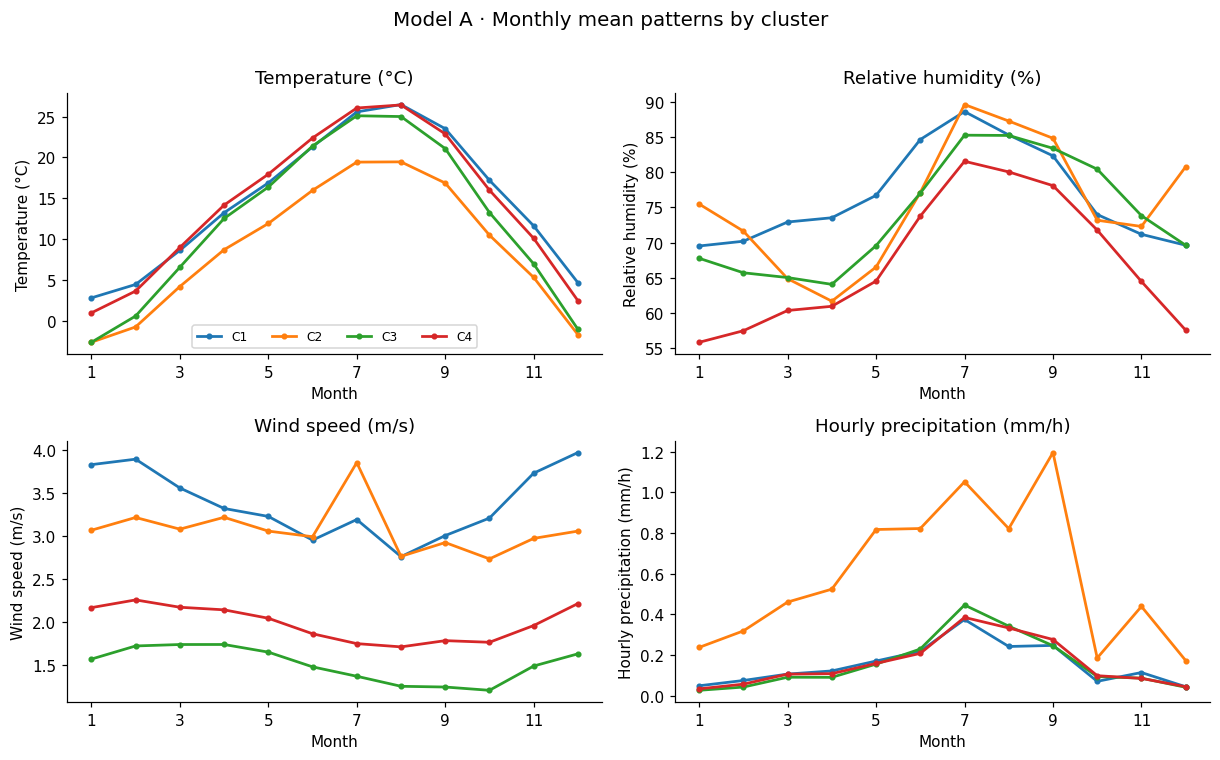

In [16]:
monthly_plot=monthly.merge(site[['station_id','cluster_A']],on='station_id',how='inner')
fig,axes=plt.subplots(2,2,figsize=(11.2,6.8))
for ax,var in zip(axes.flat,VARS):
    data=monthly_plot[monthly_plot.variable==var]
    curves=data.groupby(['cluster_A','month'])['mean'].mean().unstack(0)
    for cl in range(1,K+1):
        ax.plot(curves.index,curves[cl],marker='o',ms=3,lw=1.8,
                color=colors[(cl-1)%10],label=f'C{cl}')
    ax.set(title=VAR_NM[var],xlabel='Month',ylabel=VAR_NM[var])
    ax.set_xticks([1,3,5,7,9,11])
axes[0,0].legend(ncol=min(K,4),fontsize=8)
plt.suptitle('Model A · Monthly mean patterns by cluster',y=1.01,fontsize=13)
plt.tight_layout();plt.show()

## Model A cluster profiles ⑤ — Diurnal patterns

Hourly profiles reveal features that long-term means may conceal, such as day–night differences in temperature and humidity. Each curve is an **average 24-hour cycle**, pooled across the observation years.

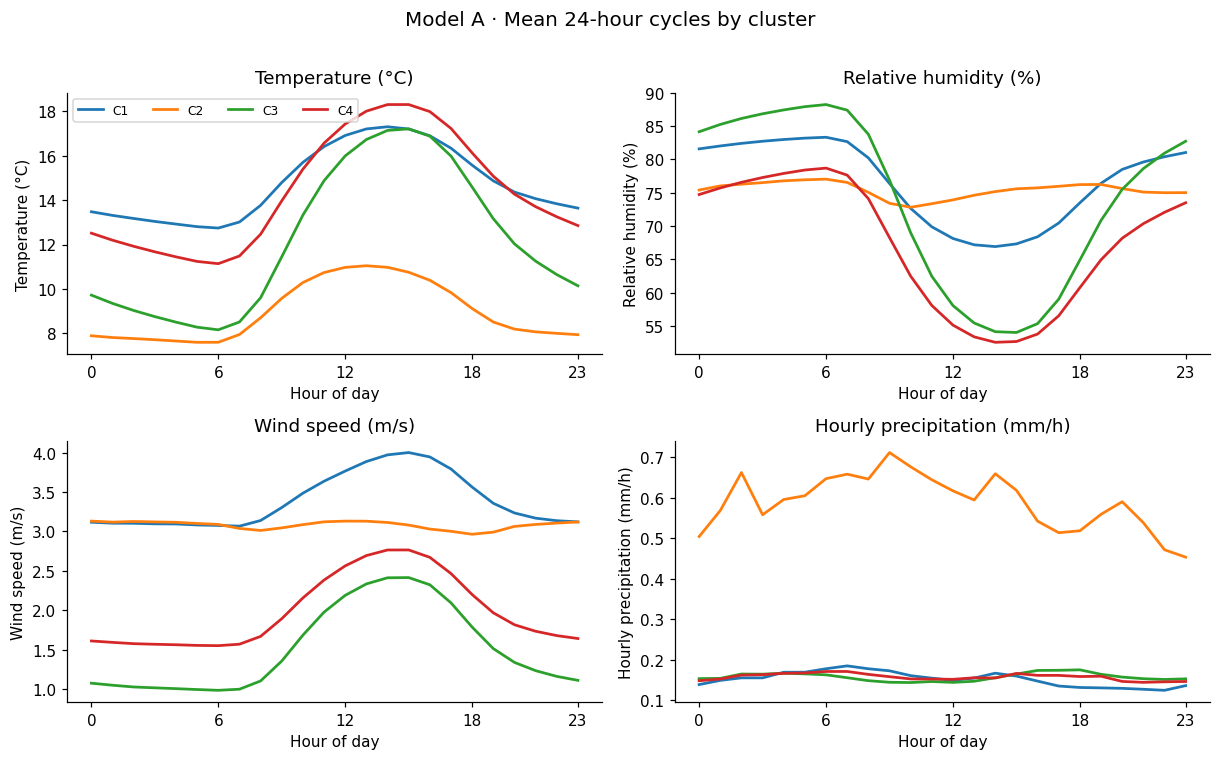

In [17]:
hourly_plot=hourly.merge(site[['station_id','cluster_A']],on='station_id',how='inner')
fig,axes=plt.subplots(2,2,figsize=(11.2,6.8))
for ax,var in zip(axes.flat,VARS):
    data=hourly_plot[hourly_plot.variable==var]
    curves=data.groupby(['cluster_A','hour'])['mean'].mean().unstack(0)
    for cl in range(1,K+1):
        ax.plot(curves.index,curves[cl],lw=1.8,color=colors[(cl-1)%10],label=f'C{cl}')
    ax.set(title=VAR_NM[var],xlabel='Hour of day',ylabel=VAR_NM[var])
    ax.set_xticks([0,6,12,18,23])
axes[0,0].legend(ncol=min(K,4),fontsize=8)
plt.suptitle('Model A · Mean 24-hour cycles by cluster',y=1.01,fontsize=13)
plt.tight_layout();plt.show()

## Model A — How to interpret the outputs

Review the mean, boxplot, temporal, and map results together:

1. Which group has relatively high temperature, humidity, wind speed, or precipitation?
2. Which group shows greater variation among stations?
3. Do monthly or hourly patterns vary across the groups?
4. Are stations with similar weather conditions also close geographically?

**Interpretation limits:** Cluster numbers are not rankings, and the output depends on the chosen features and K. Labels such as “mountain” or “coastal” would require independent information on topography and elevation.

---
## 9.3 Model B — What if temporal features are added?

Model A uses **long-term means only**. Stations with similar means may still differ in seasonal or day–night patterns. Model B adds four simple temporal features:

| Model A (4 variables) | Additional Model B feature (4 variables) |
|---|---|
| Mean temperature | Summer–winter temperature difference |
| Mean relative humidity | Summer–winter humidity difference |
| Mean wind speed | Average diurnal temperature range |
| Mean hourly precipitation | Proportion of precipitation occurring in summer |

Model B therefore uses **8 features in total**. Each feature is standardized in the same way. Model B is **not assumed to be better** than Model A.

In [18]:
rain=season.loc[season.variable=='rn_hr1',['station_id','season','count','mean']].copy()
rain['precipitation_total']=rain['count']*rain['mean']
rain_by_season=rain.pivot(index='station_id',columns='season',values='precipitation_total')
site['summer_rain_share']=site.station_id.map(rain_by_season['summer']/rain_by_season.sum(axis=1))
TIME=['ta_jja_minus_djf','hm_jja_minus_djf','ta_diurnal_range','summer_rain_share']
TIME_NAMES={'ta_jja_minus_djf':'Summer–winter temperature difference (°C)',
            'hm_jja_minus_djf':'Summer–winter humidity difference (pp)',
            'ta_diurnal_range':'Average diurnal temperature range (°C)',
            'summer_rain_share':'Summer precipitation fraction (0–1)'}
display(site[TIME].rename(columns=TIME_NAMES).describe().loc[['mean','std','min','max']].round(2))

,Summer–winter temperature difference (°C),Summer–winter humidity difference (pp),Average diurnal temperature range (°C),Summer precipitation fraction (0–1)
mean,23.30,16.78,7.54,0.51
std,2.56,6.75,2.55,0.06
min,16.22,1.69,1.12,0.30
max,28.00,39.28,11.44,0.63


## Model B — K-means and hierarchical clustering

Use the same K as in Model A. This time the input includes **4 means + 4 temporal features**, all standardized. Instead of detailed cluster profiles, we focus on changes in the geographic pattern of group membership.

The Model B dendrogram again uses station codes on the x-axis; its red dashed line represents the cut for the selected `K`.

In [19]:
X_B=StandardScaler().fit_transform(site[MEAN+TIME])
km_b=KMeans(n_clusters=K,random_state=SEED,n_init=30)
site['cluster_B_raw']=km_b.fit_predict(X_B)+1
print(f'Model B · K-means · K={K}')
display(site.cluster_B_raw.value_counts().sort_index().rename_axis('Cluster').to_frame('Number of stations'))

Model B · K-means · K=4


,Number of stations
Cluster,
1,223
2,70
3,8
4,69


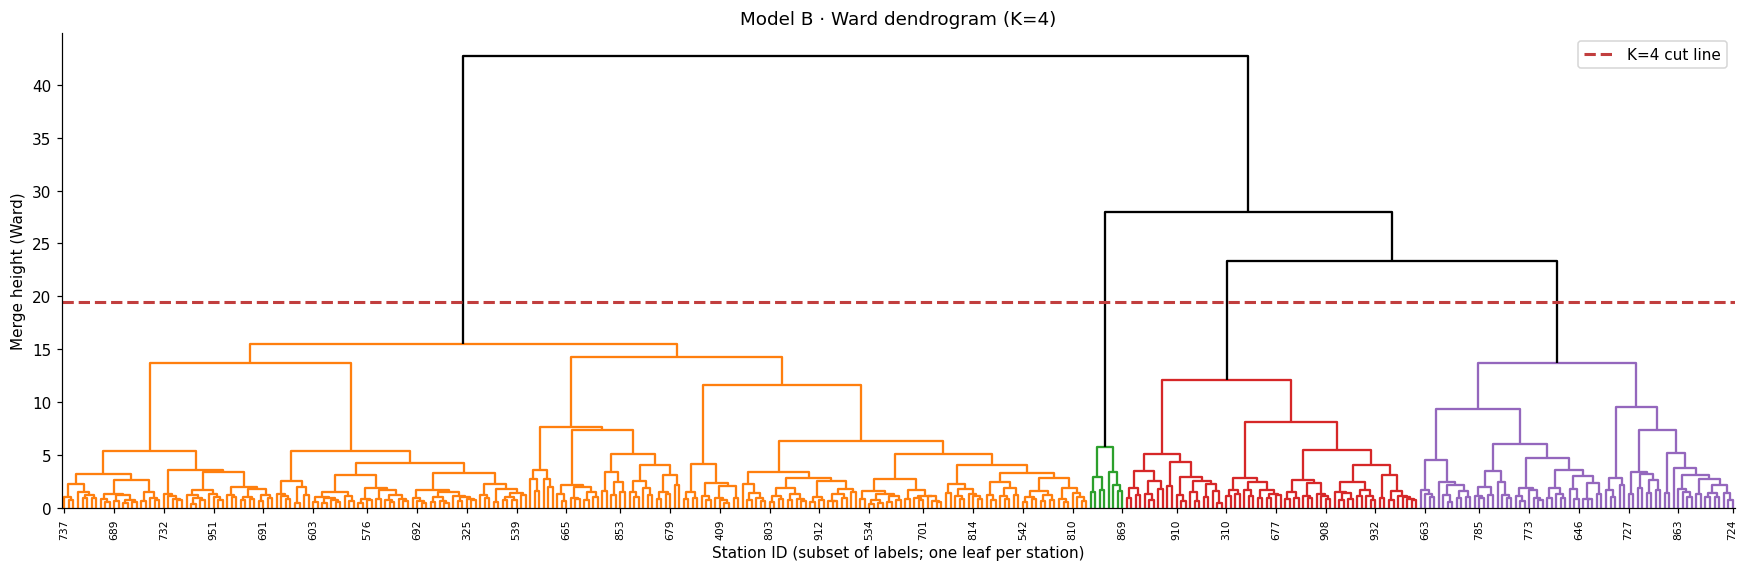

In [20]:
link_B = linkage(X_B, method='ward')
site['hier_B'] = fcluster(link_B, t=K, criterion='maxclust')
cut_B = station_dendrogram(link_B, site['station_id'], K,
                           f'Model B · Ward dendrogram (K={K})')

## Comparing Model A and Model B spatially

**Both maps show the same 370 stations.** Cluster numbers have no intrinsic meaning. For visual comparison, Model B's cluster labels are reordered to maximize overlap with Model A. Matching colors represent groups **aligned for comparison**, not necessarily equivalent groups.

Look for locations whose colors change. This demonstrates that **adding temporal information can change cluster membership**. The maps alone do not determine which model is better.

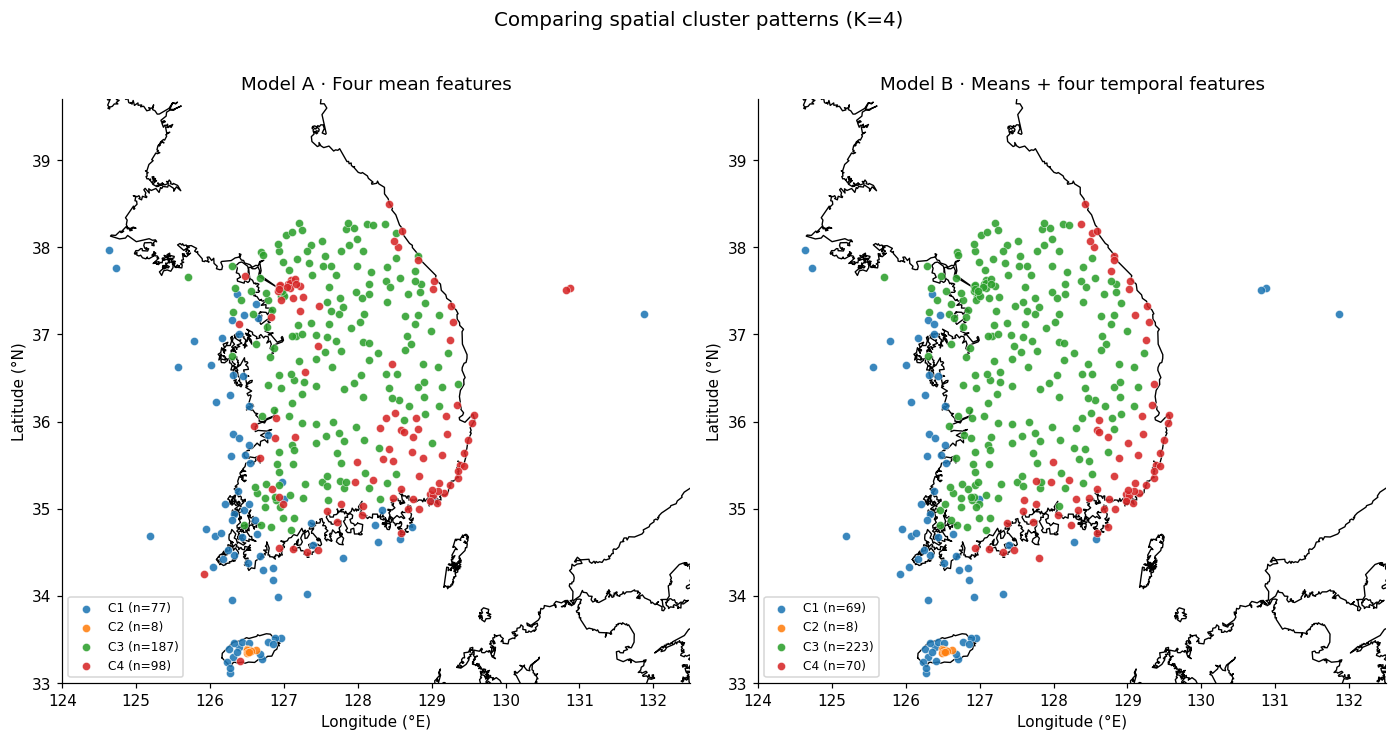

In [21]:
overlap=pd.crosstab(site.cluster_A,site.cluster_B_raw).reindex(
    index=range(1,K+1),columns=range(1,K+1),fill_value=0)
rows,cols=linear_sum_assignment(-overlap.to_numpy())
relabel={int(cols[i]+1):int(rows[i]+1) for i in range(K)}
site['cluster_B']=site.cluster_B_raw.map(relabel)
fig,axes=plt.subplots(1,2,figsize=(12.8,6.4))
cluster_map(axes[0],site.cluster_A,'Model A · Four mean features')
cluster_map(axes[1],site.cluster_B,'Model B · Means + four temporal features')
plt.suptitle(f'Comparing spatial cluster patterns (K={K})',y=1.02,fontsize=13)
plt.tight_layout();plt.show()

---
# Chapter 10. Multidimensional Scaling (MDS)

## 10.1 What is MDS?

Clustering **assigns stations to groups**. Multidimensional scaling (**MDS**) instead **places stations in two- or three-dimensional space**, trying to preserve their distances or dissimilarities.

- **Metric MDS:** Attempts to preserve the numerical distances.
- **Non-metric MDS:** Attempts to preserve the **rank order** of nearby and distant pairs.

The input has four weather variables, but MDS displays each station using two coordinates. Axes labeled MDS1 and MDS2 are **not automatically names of weather variables**.

## 10.2 Metric MDS — Representing station distances

Select a subset of stations and display distances computed from the original **four-dimensional standardized data** in two dimensions. Point colors represent Model A's K-means groups. **MDS itself does not calculate the cluster labels.**

/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:771: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:779: FutureWarning: Use metric_mds=True instead of metric=True. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


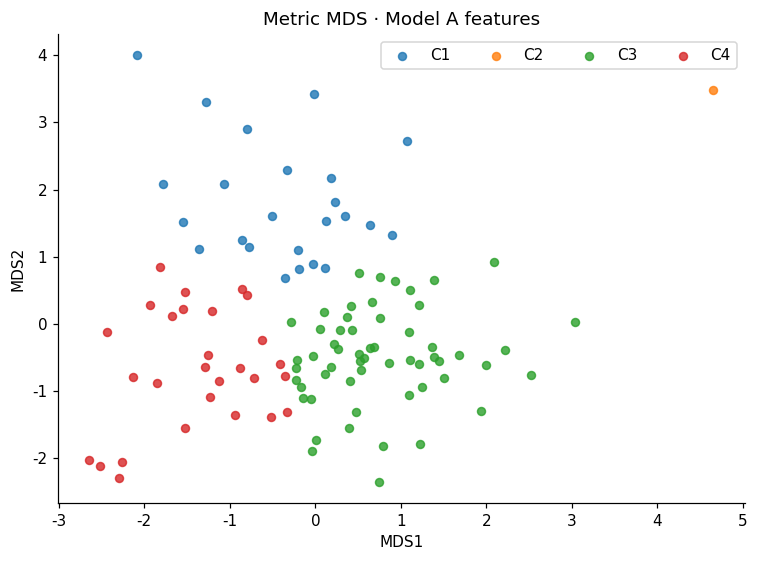

In [22]:
sample=np.sort(np.random.default_rng(SEED).choice(len(site),size=min(110,len(site)),replace=False))
D=squareform(pdist(X_A[sample]))
mds_metric=MDS(n_components=2,metric=True,dissimilarity='precomputed',
               random_state=SEED,n_init=2,max_iter=250,normalized_stress=True)
xy_metric=mds_metric.fit_transform(D)
fig,ax=plt.subplots(figsize=(7,5.2))
for cl in range(1,K+1):
    use=(site.cluster_A.to_numpy()[sample]==cl)
    ax.scatter(xy_metric[use,0],xy_metric[use,1],color=colors[(cl-1)%10],
               s=27,alpha=.8,label=f'C{cl}')
ax.set(title='Metric MDS · Model A features',xlabel='MDS1',ylabel='MDS2')
ax.legend(ncol=min(K,4));plt.tight_layout();plt.show()

## 10.3 Non-metric MDS — Preserving the order of distances

Non-metric MDS emphasizes **which station pairs are closer or farther apart**, rather than exact distance ratios. **Stress** summarizes how well the configuration reproduces the original dissimilarities. Smaller Stress generally implies less distortion, but values based on different definitions or datasets are not always directly comparable.

/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:771: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:779: FutureWarning: Use metric_mds=False instead of metric=False. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


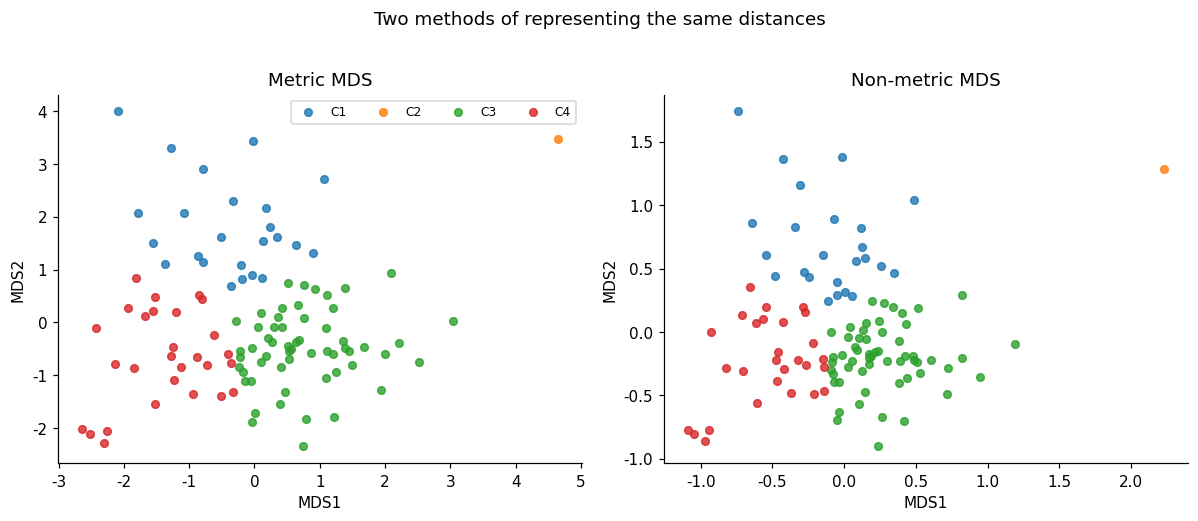

Metric MDS normalized Stress: 0.126
Non-metric MDS normalized Stress: 0.107


In [23]:
mds_nonmetric=MDS(n_components=2,metric=False,dissimilarity='precomputed',
                  random_state=SEED,n_init=2,max_iter=250,normalized_stress=True)
xy_nonmetric=mds_nonmetric.fit_transform(D)
fig,axes=plt.subplots(1,2,figsize=(11,4.6))
for ax,xy,ttl in zip(axes,[xy_metric,xy_nonmetric],['Metric MDS','Non-metric MDS']):
    for cl in range(1,K+1):
        use=(site.cluster_A.to_numpy()[sample]==cl)
        ax.scatter(xy[use,0],xy[use,1],color=colors[(cl-1)%10],s=25,alpha=.8,label=f'C{cl}')
    ax.set(title=ttl,xlabel='MDS1',ylabel='MDS2')
axes[0].legend(ncol=min(K,4),fontsize=8)
plt.suptitle('Two methods of representing the same distances',y=1.02)
plt.tight_layout();plt.show()
print('Metric MDS normalized Stress:',round(mds_metric.stress_,3))
print('Non-metric MDS normalized Stress:',round(mds_nonmetric.stress_,3))

### Interpreting the MDS plots

1. Do stations in the same cluster tend to appear close together?
2. Are group boundaries distinct or overlapping?
3. Does the relationship between near and distant pairs remain similar between Metric and Non-metric MDS?

MDS is a **summary visualization** of higher-dimensional distances. Information can be lost in two dimensions, so plot distances should not be treated as exact weather differences.

---
# Chapter 11. Discriminant Analysis

## 11.1 How is it different from clustering?

Clustering groups observations **without known labels**. Discriminant analysis starts with **known groups** and asks which variables distinguish them or predict the group of a new observation. It is therefore a form of **supervised learning**.

Because the dataset does not include official climate-zone labels, we define three **instructional groups based on station latitude**. They are neither administrative units nor official climate zones, and classification accuracy should not be interpreted as accuracy for a real climate-zone map.

In [24]:
site['region_label']=pd.qcut(site.latitude,3,labels=['South','Central','North']).astype(str)
display(site.groupby('region_label').agg(
    station_count=('station_id','size'),min_latitude=('latitude','min'),max_latitude=('latitude','max')).round(2))
X_LDA=X_A  # Use Model A's four mean weather features for LDA

,station_count,min_latitude,max_latitude
region_label,,,
Central,123,35.43,37.00
North,123,37.01,38.49
South,124,33.12,35.43


## 11.2 Basic idea of Linear Discriminant Analysis (LDA)

Linear Discriminant Analysis (**LDA**) finds directions where **differences between the known groups are large** while **variation within each group is relatively small**. Each station's projection onto a direction is a **discriminant score**.

There is one discriminant axis for two groups, and up to two axes (LD1 and LD2) for three groups.

## 11.2 Example: Distinguishing two groups

First, fit an LDA model using only the **Southern and Northern groups**, leaving out the Central group for this two-group example. If the histograms of LD1 scores overlap substantially, the weather variables do not clearly separate the two selected groups.

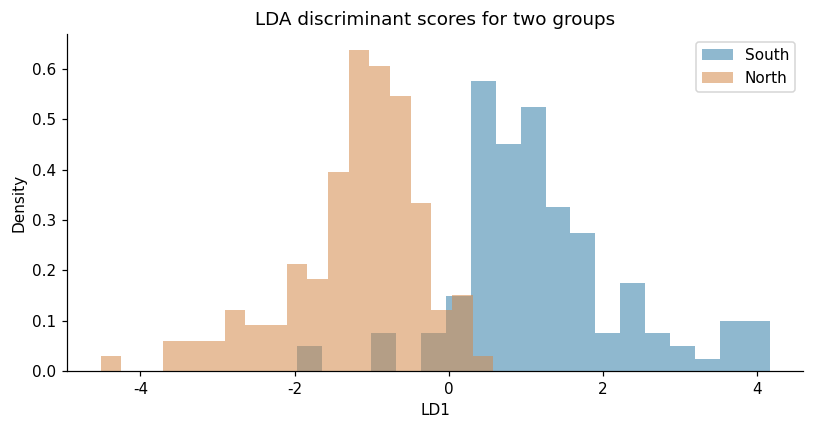

In [25]:
mask=site.region_label.isin(['South','North']).to_numpy()
x2=X_LDA[mask]; y2=site.loc[mask,'region_label'].to_numpy()
lda2=LinearDiscriminantAnalysis(n_components=1).fit(x2,y2)
scores=lda2.transform(x2)[:,0]
fig,ax=plt.subplots(figsize=(7.5,4))
for group,color in [('South','#347fa9'),('North','#d48a4a')]:
    ax.hist(scores[y2==group],bins=19,alpha=.55,label=group,density=True,color=color)
ax.set(title='LDA discriminant scores for two groups',xlabel='LD1',ylabel='Density');ax.legend()
plt.tight_layout();plt.show()

## 11.3 Three-group discriminant analysis and classification

With three groups (South, Central, and North), LDA can display stations using **two axes, LD1 and LD2**, and predict the group assignment for each station.

A **confusion matrix** compares observed and predicted groups. Diagonal entries count correctly classified stations. Accuracy assessed on the same observations used for fitting can overestimate performance on unseen data.

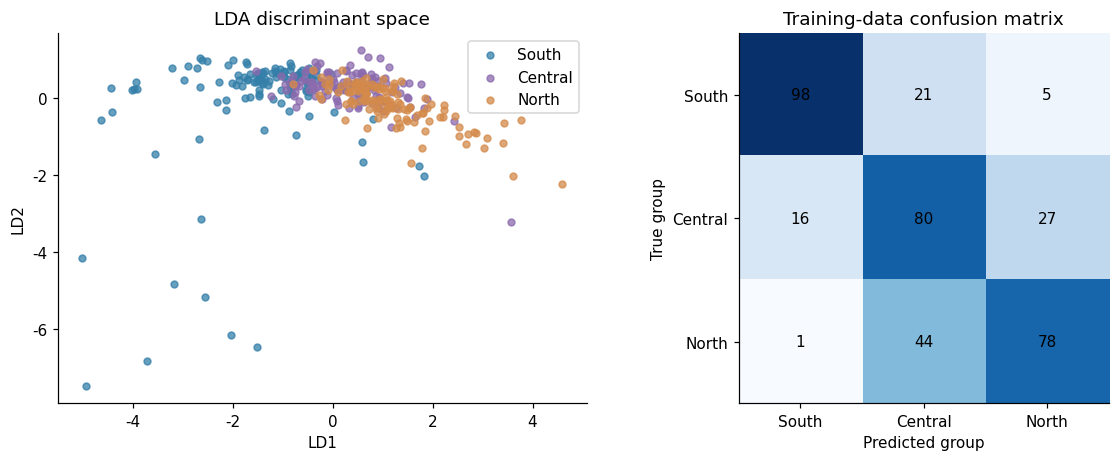

Training accuracy: 0.692


In [26]:
y3=site.region_label.to_numpy()
lda3=LinearDiscriminantAnalysis(n_components=2).fit(X_LDA,y3)
ld=lda3.transform(X_LDA)
pred=lda3.predict(X_LDA)
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for group,color in [('South','#347fa9'),('Central','#8b6aad'),('North','#d48a4a')]:
    use=y3==group
    axes[0].scatter(ld[use,0],ld[use,1],color=color,s=20,alpha=.75,label=group)
axes[0].set(title='LDA discriminant space',xlabel='LD1',ylabel='LD2');axes[0].legend()
labels=['South','Central','North']
cm=confusion_matrix(y3,pred,labels=labels)
axes[1].imshow(cm,cmap='Blues')
axes[1].set(xticks=range(3),yticks=range(3),xticklabels=labels,yticklabels=labels,
            title='Training-data confusion matrix',xlabel='Predicted group',ylabel='True group')
for i in range(3):
    for j in range(3): axes[1].text(j,i,str(cm[i,j]),ha='center',va='center')
plt.tight_layout();plt.show()
print('Training accuracy:',round(accuracy_score(y3,pred),3))

## 11.4 Cross-validation: Does the model generalize?

The previous accuracy is computed on stations that also trained the model. In **Leave-one-out cross-validation (LOOCV)**, one station is held out, an LDA model is fitted on all remaining stations, and then the held-out station is predicted. Repeat this for every station.

Comparing training accuracy with LOOCV accuracy illustrates the potential bias of evaluating a model on its training data.

In [27]:
cv_pred=cross_val_predict(LinearDiscriminantAnalysis(),X_LDA,y3,cv=LeaveOneOut())
print('Training accuracy:',round(accuracy_score(y3,pred),3))
print('LOOCV accuracy:   ',round(accuracy_score(y3,cv_pred),3))
display(pd.DataFrame(confusion_matrix(y3,cv_pred,labels=labels),
                     index=[f'True {x}' for x in labels],
                     columns=[f'Predicted {x}' for x in labels]))

Training accuracy: 0.692
LOOCV accuracy:    0.678


,Predicted South,Predicted Central,Predicted North
True South,96,23,5
True Central,16,78,29
True North,1,45,77
